In [3]:
### build basic chat bot using langgrph(GRAPHapi)

### importent of langgrap
1. EDGE
2.NODE
3.STATE
why state graph beacuse node data which is stored can access with in the specific nodes

In [9]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import Annotated, TypedDict
# anntatition is reducer when i create a data get and store one by one inise the list messgaes
from langgraph.graph.message import add_messages



In [10]:
class State(TypedDict):
    messages: Annotated[list[dict], add_messages]
graph_builder_obj = StateGraph(State)


In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()
API_KEY=os.getenv("GROQ_API_KEY")
os.environ["GROQ_API_KEY"]=API_KEY
Travelly=os.getenv("TAVILY_API_KEY")
os.environ["TAVILY_API_KEY"]=Travelly
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
llm = ChatGroq(model="qwen/qwen3-32b", api_key=API_KEY)

In [12]:
# another way to initialize
# llm = init_chat_model("groq:llama3-8b-8192")
# print(llm)

In [37]:
def chatbot(state: State):
    # last_msg = state["messages"][-1]        # Get the last user message
    # user_text = last_msg["content"]
    # ai_response = llm.invoke(user_text)     # ✅ Only pass text
    # return {"messages": [ai_response]}

    return {"messages": [llm.invoke(state["messages"])]} 

In [36]:
# start building the graph

graph_builder_obj.add_node("chatbot_llm", chatbot)
graph_builder_obj.add_edge(START, "chatbot_llm")
graph_builder_obj.add_edge("chatbot_llm", END)




Adding a node to a graph that has already been compiled. This will not be reflected in the compiled graph.


ValueError: Node `chatbot_llm` already present.

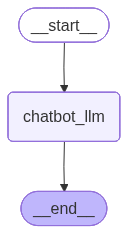

In [130]:
## visualization graph
from IPython.display import display, Markdown, Image
try:
    # compile the StateGraph to a graph builder object first
    graph_builder=graph_builder_obj
    graph_builder = graph_builder.compile()
    # prefer rendering a PNG if available
    try:
        img_bytes = graph_builder.get_graph().draw_mermaid_png(max_retries=3, retry_delay=1.0)
        display(Image(img_bytes))
    except Exception:
        # fallback to showing raw mermaid code in case rendering isn't available
        mermaid_code = graph_builder.get_mermaid()
        display(Markdown(f"```mermaid\n{mermaid_code}\n```"))
except Exception as e:
    print("Error displaying graph:", e)

In [131]:
from langchain_core.messages import HumanMessage

graph_builder = graph_builder_obj.compile()

# 8️⃣ Invoke the graph
response = graph_builder.invoke(
    {"messages": [HumanMessage(content="Hi")]}  # send as HumanMessage
)

# 9️⃣ Print the AI response
last_msg = response["messages"][-1]
print("AI RESPONSE:", last_msg)

AI RESPONSE: content='<think>\nOkay, the user sent "Hi". That\'s pretty open-ended. I need to figure out how to respond. Since they just said "Hi", maybe they\'re starting a conversation. I should greet them back and ask how I can help. Let me make sure my response is friendly and inviting. Maybe something like, "Hello! How can I assist you today?" That should work. I don\'t want to assume they need anything specific, so keeping it general is good. Let me check for any typos and ensure the tone is positive. Yep, that looks good.\n</think>\n\nHello! How can I assist you today? 😊' additional_kwargs={} response_metadata={'token_usage': {'completion_tokens': 132, 'prompt_tokens': 9, 'total_tokens': 141, 'completion_time': 0.284763908, 'prompt_time': 0.000207097, 'queue_time': 0.04402812, 'total_time': 0.284971005}, 'model_name': 'qwen/qwen3-32b', 'system_fingerprint': 'fp_5cf921caa2', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None} id='run--a3e32c7a-5d4a-4827-a5d3-a

### creteion the mcp tools


In [132]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_results=3)
tool.invoke({"query": "taltest lg stock in news"})


{'query': 'taltest lg stock in news',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://finance.yahoo.com/news/lg-electronics-india-lists-nse-055600102.html',
   'title': 'LG ELECTRONICS INDIA LISTS ON NSE',
   'content': 'LG Electronics (LG) today announced the listing of its subsidiary, LG Electronics India Limited (LGEIL), on the National Stock Exchange of India',
   'score': 0.42162386,
   'raw_content': None},
  {'url': 'https://www.livemint.com/market/stock-market-news/lg-electronics-shares-brokerages-see-up-to-80-upside-potential-what-makes-them-bullish-after-stellar-debut-11760423210459.html',
   'title': 'LG Electronics shares: Brokerages see up to 80% upside ...',
   'content': "LG Electronics' share price got listed at ₹1,715 on the BSE — a premium of ₹575, or 50.44 per cent, over the issue price of ₹1,140. On the NSE,",
   'score': 0.37175277,
   'raw_content': None},
  {'url': 'https://www.moneycontrol.com/news/business/ipo/lg-elec

In [19]:
#### write the doc strinh

In [20]:
def multipal(a, b):
    """
    This function takes two arguments, a and b, and returns their product.
    
    Parameters:
    a (int): The first integer.
    b (int): The second integer.
    
    Returns:
    int: The product of a and b
    """
    return a * b

In [133]:
tools=[tool,multipal]
# bin with all tools
# after next bind all the tools into single tools


In [134]:
llm_with_tool = llm.bind_tools(tools)
llm_with_tool.invoke("What is the capital of India?")

AIMessage(content='', additional_kwargs={'reasoning_content': 'Okay, the user is asking for the capital of India. I need to provide an accurate answer. Let me think about the tools available. There\'s the Tavily Search function which can retrieve up-to-date information. The question is straightforward, so maybe a basic search would suffice. I should check if there\'s any recent change, but I recall that New Delhi has been the capital for a long time. Still, to ensure correctness, I\'ll use the Tavily Search. Let me set the parameters: the query is "capital of India", no need for specific dates or domains. I\'ll use the default settings. The other tool, multipal, isn\'t relevant here. So, the function call should be to Tavily Search with the query "capital of India".\n', 'tool_calls': [{'id': 'zvkbdqdxa', 'function': {'arguments': '{"query":"capital of India"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 186, 'prompt_tokens':

In [148]:

# this is diffrent from the above one


from IPython.display import display, Markdown, Image
from langgraph.graph import StateGraph, START, END
### build basic chat bot using langgrph(GRAPHapi)
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

# node deination

builder=StateGraph(State)

# create tool calling the llm model
def tool_calling_llm_if_answer_is_extrenal(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

# create a node
builder.add_node("llm_node", tool_calling_llm_if_answer_is_extrenal)
# inide the tools node has multipal tools
builder.add_node("tool", ToolNode(tools))


# add the edges
builder.add_edge(START, "llm_node")
builder.add_conditional_edges(
    "llm_node",
    tools_condition,
    {
        True: "tool",
        False: END
    }
    # this will help to decide which node to go next wheater question is related to tool call it is True by llm call the tool node other wise END
)
# builder.add_edge("tool", END)
# After tool execution, go back to llm_node
# this process is call as react


builder_compile=builder.compile(checkpointer=memory)
# 8️⃣ Invoke the graph



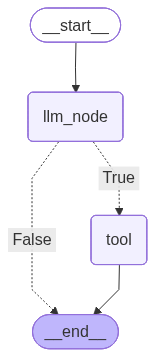

In [136]:

try:
        img_bytes = builder_compile.get_graph().draw_mermaid_png(max_retries=3, retry_delay=1.0)
        display(Image(img_bytes))
except Exception:
        # fallback to showing raw mermaid code in case rendering isn't available
        mermaid_code = builder_compile.get_mermaid()
        display(Markdown(f"```mermaid\n{mermaid_code}\n```"))

In [152]:
# crete the histore reducer
config={"configurable": {"thread": "1"}}
response=graph_builder.invoke({
    "messages": [HumanMessage(content="recent new about  karnataka folad crash in india and also do multiplication 6 * 7 ")],
    "configurable": {"thread": "1"}
})

response["messages"]

# for m in response["messages"]:
#     m.pretty_print()
    


[HumanMessage(content='recent new about  karnataka folad crash in india and also do multiplication 6 * 7 ', additional_kwargs={}, response_metadata={}, id='56b1ce13-ccfc-4137-aef2-bcc6d74fc297'),
 AIMessage(content='<think>\nOkay, the user is asking about recent news on a Karnataka folad crash in India and also wants to know the multiplication of 6 and 7. Let me start by breaking down the query.\n\nFirst, "Karnataka folad crash" – I need to figure out what that refers to. "Folad" might be a typo or a mispronunciation. Karnataka is a state in India, so maybe there was an accident involving a vehicle or aircraft there. I should check recent news reports for any crashes in Karnataka. Let me think of possible spellings. Could it be "Folad" as in a brand name? Maybe "Folad" is a local term or a specific model. Alternatively, it could be a misspelling of another word, like "flood" or "road." \n\nNext, the multiplication part is straightforward: 6 * 7. The answer is 42, but I should confirm t

In [142]:

# this is diffrent from the above one


from IPython.display import display, Markdown, Image
from langgraph.graph import StateGraph, START, END
### build basic chat bot using langgrph(GRAPHapi)
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# node deination

builder_graph=StateGraph(State)

# create tool calling the llm model
def tool_calling_llm_if_answer_is_extrenal(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

# create a node

builder_graph.add_node("llm_node", tool_calling_llm_if_answer_is_extrenal)
# inide the tools node has multipal tools
builder_graph.add_node("tool", ToolNode(tools))


# add the edges
builder_graph.add_edge(START, "llm_node")
builder_graph.add_conditional_edges(
    "llm_node",
    tools_condition,
    {
        True: "tool",
        False: END
    }
    # this will help to decide which node to go next wheater question is related to tool call it is True by llm call the tool node other wise END
)
# After tool execution, go back to llm_node
# this process is call as react
builder_graph.add_edge("tool", "llm_node")

builder_compile_2=builder_graph.compile()
# 8️⃣ Invoke the graph



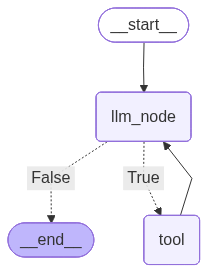

In [143]:

try:
        img_bytes = builder_compile_2.get_graph().draw_mermaid_png(max_retries=3, retry_delay=1.0)
        display(Image(img_bytes))
except Exception:
        # fallback to showing raw mermaid code in case rendering isn't available
        mermaid_code = builder_compile_2.get_mermaid()
        display(Markdown(f"```mermaid\n{mermaid_code}\n```"))

In [144]:
# crete the histore reducer


response=builder_compile_2.invoke({"messages": [HumanMessage(content="5*6 multipal  and tell me new things about AI")]})

response["messages"][-1].content

for m in response["messages"]:
    m.pretty_print()
    


KeyError: 'tools'

#### memory pointer 

In [ ]:
# this is diffrent from the above one


from IPython.display import display, Markdown, Image
from langgraph.graph import StateGraph, START, END
### build basic chat bot using langgrph(GRAPHapi)
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver


memory=MemorySaver()
# node deination

builder_graph=StateGraph(State)

# create tool calling the llm model
def tool_calling_llm_if_answer_is_extrenal(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

# create a node

builder_graph.add_node("llm_node", tool_calling_llm_if_answer_is_extrenal)
# inide the tools node has multipal tools
builder_graph.add_node("tool", ToolNode(tools))


# add the edges
builder_graph.add_edge(START, "llm_node")
builder_graph.add_conditional_edges(
    "llm_node",
    tools_condition,
    {
        True: "tool",
        False: END
    }
    # this will help to decide which node to go next wheater question is related to tool call it is True by llm call the tool node other wise END
)
# After tool execution, go back to llm_node
# this process is call as react
builder_graph.add_edge("tool", "llm_node")


builder_compile_2=builder_graph.compile(checkpointer=memory)
# 8️⃣ Invoke the graph



In [157]:

config = {"configurable": {"thread_id": "thread-1"}}
response = builder_compile_2.invoke({
    "messages": [HumanMessage(content="5*6 multipal and tell me new things about AI")],
    "configurable": {"thread_id": "thread-1"}  # ✅ required for checkpointer
})

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

### human in loops

lets says the llm---> tools call---> hunman approve -->llm back --->deccsion --> end